# Capstone - Content Action Playbook

This notebook consolidates the warehouse contract, baseline, model validation, signal audit, and rule-based action playbook. It uses saved notebook results and local cached files only; it does not query the warehouse or download new data.

## 1. Question

The lane is CTR / Engagement Opportunity Scoring. The decision is which pages an editor or SEO analyst should inspect first for a possible CTR or metadata opportunity. The output is a ranked review queue, evaluated with Precision@K, and is decision support rather than an automatic publishing system.

This is not plain classification: one yes/no decision per page does not directly prioritize limited review time. It is not clustering: pages are ordered against measured outcomes rather than grouped into unlabeled segments. GA4 engagement is only partly available, so CTR gap is the main review signal; decline is a separate later outcome.

In [1]:
from pathlib import Path
import ast
import json
import re

import numpy as np
import pandas as pd
from IPython.display import SVG, display

ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "work" / "notebooks" / "capstone.ipynb").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate the repository root from the notebook directory.")

OUT = ROOT / "work" / "outputs"
NOTEBOOKS = ROOT / "work" / "notebooks"
FIGURES = ROOT / "work" / "figures"


def saved_stream(notebook_path, cell_id):
    notebook = json.loads(notebook_path.read_text(encoding="utf-8"))
    cell = next((item for item in notebook["cells"] if item.get("id") == cell_id), None)
    if cell is None:
        raise KeyError(f"Cell {cell_id!r} was not found in {notebook_path.name}.")
    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            raise RuntimeError(
                f"Saved output for {cell_id!r} contains {output.get('ename')}: {output.get('evalue')}"
            )
        if output.get("output_type") == "stream":
            text = output.get("text", "")
            return "".join(text) if isinstance(text, list) else text
    raise ValueError(f"Cell {cell_id!r} has no saved text output.")


required_files = [
    NOTEBOOKS / "w03_data_contract.ipynb",
    NOTEBOOKS / "w04_baseline_score.ipynb",
    NOTEBOOKS / "w05_model.ipynb",
    NOTEBOOKS / "w06_validation_audit.ipynb",
    NOTEBOOKS / "w07_action_playbook.ipynb",
    OUT / "w06_fold_results_grouped.csv",
    OUT / "w06_random_vs_grouped.csv",
    OUT / "w06_ablation.csv",
    OUT / "w07_metrics.json",
    OUT / "action_playbook_queue.csv",
    OUT / "action_playbook_review_top50.csv",
    OUT / "action_playbook_check_top50.csv",
    OUT / "baseline_action_score.csv",
]
missing_files = [str(path.relative_to(ROOT)) for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError("Required local project outputs are missing: " + ", ".join(missing_files))

print("Project root:", ROOT)
print("Source mode: saved notebook outputs and local caches only; no warehouse query.")

Project root: C:\Users\lukau\FlyRank_intership
Source mode: saved notebook outputs and local caches only; no warehouse query.


## 2. Data

The W3 contract checks the March warehouse partition and aggregates daily rows to one row per client and content item for that month. W3 joins the daily fact table to content and client dimensions and checks grain, date coverage, and the GA4 availability flag. Its same-month CTR proxy is kept separate from the later evaluation.

W4-W7 use the cached analysis population, March-May features, and June outcomes. The reported population is smaller than the raw March fact slice because pages without the required scoreable search evidence are not eligible. Only pseudonymous keys needed for grouping or joining are present in the local analysis outputs; this capstone does not display identifiers, URLs, or queries.

In [2]:
w3_path = NOTEBOOKS / "w03_data_contract.ipynb"
daily_text = saved_stream(w3_path, "85e93190")
summary_text = saved_stream(w3_path, "d3e29686")
availability_text = saved_stream(w3_path, "860fbc42")

row_match = re.search(r"rows:\s*([\d,]+)", daily_text)
mean_match = re.search(r"mean_daily_ctr_pct:\s*([\d.]+)", daily_text)
weighted_match = re.search(r"weighted_ctr_pct:\s*([\d.]+)", daily_text)
summary_match = re.search(
    r"^\s*(\d+)\s+(\d+)\s+(\d+)\s+(\d{4}-\d{2}-\d{2})\s+(\d{4}-\d{2}-\d{2})\s*$",
    summary_text,
    re.MULTILINE,
)
availability_match = re.search(
    r"^\s*(\d+)\s+([\d.]+)\s+([\d.]+)\s*$",
    availability_text,
    re.MULTILINE,
)
if not all((row_match, mean_match, weighted_match, summary_match, availability_match)):
    raise ValueError("Could not parse the saved W3 contract output; review the source notebook output.")

contract_rows = int(row_match.group(1).replace(",", ""))
mean_daily_ctr = float(mean_match.group(1))
weighted_ctr = float(weighted_match.group(1))
content_count = int(summary_match.group(2))
client_count = int(summary_match.group(3))
start_date, end_date = summary_match.group(4), summary_match.group(5)
ga4_rows = int(float(availability_match.group(2)))
ga4_share_pct = float(availability_match.group(3))

metrics = json.loads((OUT / "w07_metrics.json").read_text(encoding="utf-8"))
queue_scope = pd.read_csv(
    OUT / "action_playbook_queue.csv",
    usecols=["client_hash_id", "content_hash_id"],
)

print(f"W3 contract: {contract_rows:,} daily rows; {content_count:,} contents; {client_count:,} clients; {start_date} to {end_date}.")
print(f"GA4 availability: {ga4_rows:,} of {contract_rows:,} rows ({ga4_share_pct:.1f}%).")
print(f"CTR check: mean page-day CTR {mean_daily_ctr:.3f}%; weighted CTR {weighted_ctr:.3f}%. The weighted value gives higher-impression rows more weight.")
print(f"W4-W7 cached analysis population: {len(queue_scope):,} pages from {queue_scope['client_hash_id'].nunique():,} clients.")
print("June-outcome base rates:", {name: round(value, 3) for name, value in metrics["base_rates"].items()})

W3 contract: 9,841,378 daily rows; 331,437 contents; 55 clients; 2026-03-01 to 2026-03-31.
GA4 availability: 413,966 of 9,841,378 rows (4.2%).
CTR check: mean page-day CTR 0.308%; weighted CTR 0.293%. The weighted value gives higher-impression rows more weight.
W4-W7 cached analysis population: 90,966 pages from 37 clients.
June-outcome base rates: {'y_decline': 0.704, 'y_low_ctr': 0.57}


## 3. Methodology

The W3 contract defines five month-level features that are knowable at scoring time: impressions, average position, days with data, content age, and position volatility. In W4-W7 these are expanded into a fifteen-column feature vector using March-May exposure, CTR gap, position tier, and momentum features. June is held out for outcome labels.

The decline proxy marks a page when June impressions are below the stated fraction of May impressions. The low-CTR proxy marks pages whose June CTR is below the expected CTR for their position tier, and is unlabelled when June impressions are too small for a stable rate. Evaluation uses five client-grouped folds so a client is held out from training in its test fold.

W3 also demonstrates a same-month leakage trap: adding the CTR used to define its proxy label produces a leaky ranking score. That is not evidence of forecast skill. The later W4-W7 pipeline uses future June outcomes and excludes June and label-derived fields from the features.

In [3]:
w05_path = NOTEBOOKS / "w05_model.ipynb"
w05_notebook = json.loads(w05_path.read_text(encoding="utf-8"))
feature_names = None
for cell in w05_notebook["cells"]:
    for output in cell.get("outputs", []):
        if output.get("output_type") != "stream":
            continue
        text = output.get("text", "")
        text = "".join(text) if isinstance(text, list) else text
        feature_match = re.search(r"(?m)^\s*\d+\s+features:\s*(\[[^\n]*\])", text)
        if feature_match:
            feature_names = ast.literal_eval(feature_match.group(1))
            break
    if feature_names is not None:
        break
if feature_names is None:
    raise ValueError("Could not find the saved W5 feature list.")

folds = pd.read_csv(OUT / "w06_fold_results_grouped.csv")
fold_count = folds["fold"].nunique()
if "split" not in folds.columns or set(folds["split"].dropna()) != {"grouped_by_client"}:
    raise ValueError("The cached W6 results are not the client-grouped evaluation.")

leak_text = saved_stream(w3_path, "42a83614")
leak_lines = [
    line for line in leak_text.splitlines()
    if line.startswith(("labelled pages:", "honest P@20", "LEAKY P@20"))
]
if not leak_lines:
    raise ValueError("Could not find the saved W3 leakage-check results.")

print(f"W5 feature vector ({len(feature_names)} features):")
print(", ".join(feature_names))
print("June outcomes: y_decline = imp_jun < 0.8 * imp_may; y_low_ctr = June CTR below tier expectation when June impressions are at least 100, otherwise unlabelled.")
print(f"W6 validation: {fold_count} client-grouped folds; each fold holds out clients.")
print("Saved W3 same-month leakage check:")
print("\n".join(leak_lines))

W5 feature vector (15 features):
log_imp_early, log_imp_may, log_imp_feat, recent_ratio_c, slip, log_ctr_feat, ctr_gap, tier_expected_ctr, log_pos_feat, days_with_imp_feat, tier_deep, tier_page_1, tier_page_3_5, tier_striking, tier_top_3
June outcomes: y_decline = imp_jun < 0.8 * imp_may; y_low_ctr = June CTR below tier expectation when June impressions are at least 100, otherwise unlabelled.
W6 validation: 5 client-grouped folds; each fold holds out clients.
Saved W3 same-month leakage check:
labelled pages: 101441 | base rate: 0.691
honest P@20 (position only): 0.9
LEAKY P@20 (+ ctr_month):    1.0
honest P@20 after removal:   0.9


## 4. Results (vs baseline)

The main comparison uses the same five client-grouped test folds for the random forest and the frozen W4 rule. Precision@50 measures the positive share among the first fifty pages in each fold; AUC is included as a whole-ranking measure. The table reports fold means and the observed base rate. These are retrospective decision-support results, not causal estimates.

In [4]:
fold_results = pd.read_csv(OUT / "w06_fold_results_grouped.csv")
if "split" not in fold_results.columns or set(fold_results["split"].dropna()) != {"grouped_by_client"}:
    raise ValueError("Expected the cached client-grouped W6 results.")

result_rows = []
for label in ["y_decline", "y_low_ctr"]:
    label_rows = fold_results[fold_results["label"] == label]
    base_rows = label_rows.drop_duplicates("fold")
    base_rate = np.average(base_rows["base_rate"], weights=base_rows["n_test"])
    p50_by_fold = label_rows.pivot(index="fold", columns="ranking", values="P@50")
    forest_wins = int((p50_by_fold["random_forest"] > p50_by_fold["baseline_rule"]).sum())
    for ranking in ["baseline_rule", "random_forest"]:
        model_rows = label_rows[label_rows["ranking"] == ranking]
        result_rows.append({
            "outcome": label,
            "ranking": ranking,
            "base_rate": base_rate,
            "mean P@20": model_rows["P@20"].mean(),
            "mean P@50": model_rows["P@50"].mean(),
            "mean AUC": model_rows["auc"].mean(),
            "forest P@50 wins vs rule": f"{forest_wins}/{fold_count}" if ranking == "random_forest" else "reference",
        })

result_table = pd.DataFrame(result_rows)
for column in ["base_rate", "mean P@20", "mean P@50", "mean AUC"]:
    result_table[column] = result_table[column].round(3)
display(result_table)

signal_text = saved_stream(NOTEBOOKS / "w04_baseline_score.ipynb", "1c-signal-checks-code")
print("W4 signal checks (saved aggregate output):")
print(signal_text)

,outcome,ranking,base_rate,mean P@20,mean P@50,mean AUC,forest P@50 wins vs rule
0,y_decline,baseline_rule,0.704,0.77,0.764,0.533,reference
1,y_decline,random_forest,0.704,0.86,0.852,0.597,3/5
2,y_low_ctr,baseline_rule,0.570,0.70,0.756,0.590,reference
3,y_low_ctr,random_forest,0.570,0.97,0.972,0.760,5/5


W4 signal checks (saved aggregate output):
Signal A: weighted CTR by position tier (n >= 50)
position_tier       n  weighted_ctr_pct
        top_3  2472.0          0.474200
       page_1 38970.0          0.319737
     striking 22099.0          0.322561
     page_3_5 22778.0          0.149093
         deep  4647.0          0.034624
Signal A verdict: MIXED

Signal B: June decline rate by May slip bucket (n >= 50)
slip_bucket     n  y_decline_rate
          0 26911        0.715172
     0-0.25 15180        0.715020
   0.25-0.5 19795        0.728669
    0.5-0.9 28042        0.677341
      >=0.9  1038        0.540462
base rate y_decline: 0.704
Signal B verdict: OPPOSITE



## 5. Limitations

The outcomes cover one observed month and a limited set of clients. The low-CTR target partly measures persistence because the historical CTR gap is also available to the model. A client-grouped split reduces client leakage, but it does not test a different future month or prove that an edit will improve performance.

The playbook is a review aid, not an automatic publishing or impression-decline system. A wrong call can spend reviewer time, and skipping the human check can still lead to an unsuitable edit. A false technical-check route also uses data or engineering review capacity. The reported cost figures are decision-support estimates, not monetary claims. CTR-positive rates are measured only on labelled pages; the estimate assumes unlabelled pages have the same rate.

In [5]:
random_vs_grouped = pd.read_csv(OUT / "w06_random_vs_grouped.csv")
ablation = pd.read_csv(OUT / "w06_ablation.csv")
review_top50 = pd.read_csv(OUT / "action_playbook_review_top50.csv")

rf_decline = random_vs_grouped[
    (random_vs_grouped["label"] == "y_decline")
    & (random_vs_grouped["ranking"] == "random_forest")
].iloc[0]
low_ctr_ablation = ablation[ablation["label"] == "y_low_ctr"].set_index("variant")
full_low_ctr = low_ctr_ablation.loc["full feature set"]
without_ctr = low_ctr_ablation.loc["without CTR family"]

refresh_count = int((review_top50["action"] == "review_content_refresh").sum())
review_clients = int(review_top50["client_hash_id"].nunique())
review_decline = review_top50["y_decline"].mean()
base_decline = metrics["base_rates"]["y_decline"]

CAPACITY = 50
REVIEW_MINUTES_PER_PAGE = 12  # W7 assumption
baseline_all = pd.read_csv(
    OUT / "baseline_action_score.csv",
    usecols=["baseline_action_score", "y_low_ctr"],
)
baseline_top50 = baseline_all.sort_values(
    "baseline_action_score", ascending=False
).head(CAPACITY)

def cost_estimate(name, rate, reviewed_pages):
    expected_true = rate * reviewed_pages
    return {
        "queue": name,
        "reviewed_pages": reviewed_pages,
        "estimated_true_low_ctr": expected_true,
        "reviewer_hours": reviewed_pages * REVIEW_MINUTES_PER_PAGE / 60,
        "wasted_review_pages": reviewed_pages - expected_true,
    }

cost_table = pd.DataFrame([
    cost_estimate("playbook top 50", review_top50["y_low_ctr"].mean(), len(review_top50)),
    cost_estimate("W4 baseline top 50", baseline_top50["y_low_ctr"].mean(), len(baseline_top50)),
    cost_estimate("random selection", metrics["base_rates"]["y_low_ctr"], CAPACITY),
])
print(f"Cost assumption: {REVIEW_MINUTES_PER_PAGE} reviewer minutes per page; capacity {CAPACITY} pages.")
display(cost_table.round(2))

print(f"Review top-50 coverage: {review_clients} clients out of {queue_scope['client_hash_id'].nunique()} in the analysis population.")
print(f"Review top-50 content-refresh routes: {refresh_count}; June decline rate: {review_decline:.3f} versus base rate {base_decline:.3f}.")
print(f"W6 random-row vs grouped random-forest y_decline P@50: {rf_decline['P@50 random']:.3f} vs {rf_decline['P@50 grouped']:.3f}; AUC: {rf_decline['AUC random']:.3f} vs {rf_decline['AUC grouped']:.3f}.")
print(f"W6 y_low_ctr ablation: full-feature P@50 {full_low_ctr['P@50 mean']:.3f}, AUC {full_low_ctr['AUC mean']:.3f}; without CTR-family P@50 {without_ctr['P@50 mean']:.3f}, AUC {without_ctr['AUC mean']:.3f}.")

stability_path = OUT / "w06_fold_stability.csv"
if stability_path.is_file():
    stability = pd.read_csv(stability_path)
    interval = stability[
        (stability["label"] == "y_decline")
        & (stability["ranking"] == "random_forest")
        & (stability["K"] == 50)
    ]
    if not interval.empty:
        row = interval.iloc[0]
        print(f"W6 grouped-fold bootstrap interval for y_decline P@50 difference: [{row['boot90_lo']:.3f}, {row['boot90_hi']:.3f}] (observed folds only).")
print("These checks do not establish performance in a new month or an effect from changing a page.")

Cost assumption: 12 reviewer minutes per page; capacity 50 pages.


,queue,reviewed_pages,estimated_true_low_ctr,reviewer_hours,wasted_review_pages
0,playbook top 50,50,47.96,10.0,2.04
1,W4 baseline top 50,50,38.04,10.0,11.96
2,random selection,50,28.51,10.0,21.49


Review top-50 coverage: 9 clients out of 37 in the analysis population.
Review top-50 content-refresh routes: 0; June decline rate: 0.680 versus base rate 0.704.
W6 random-row vs grouped random-forest y_decline P@50: 1.000 vs 0.852; AUC: 0.694 vs 0.597.
W6 y_low_ctr ablation: full-feature P@50 0.972, AUC 0.760; without CTR-family P@50 0.944, AUC 0.624.
W6 grouped-fold bootstrap interval for y_decline P@50 difference: [-0.008, 0.220] (observed folds only).
These checks do not establish performance in a new month or an effect from changing a page.


## 6. Ranked recommendations

Use the queue to decide what a person should inspect first. A CTR-gap page goes to a title, snippet, and intent check. A page with a collapsed May signal goes to a technical check before any content rewrite. A suspected measurement issue is verified before editorial action. The rules-based archetypes are review descriptions, not clusters or causal explanations.

In [6]:
review_top50 = pd.read_csv(
    OUT / "action_playbook_review_top50.csv",
    usecols=["playbook_rank", "client_hash_id", "action", "reason_code", "evidence_strength", "model_prob"],
)
check_top50 = pd.read_csv(
    OUT / "action_playbook_check_top50.csv",
    usecols=["playbook_rank", "action", "reason_code", "evidence_strength"],
)

human_guidance = {
    "review_ctr_metadata": "Compare the page title and snippet with intent and the observed CTR gap; a human approves any edit.",
    "review_content_refresh": "Review the decline evidence after technical causes are checked.",
    "check_technical_first": "Check indexing, redirects, measurement, and tracking before a content change.",
    "verify_data_first": "Confirm data coverage and measurement before editorial action.",
    "verify_then_review": "Verify the observed rise, then review if it remains.",
    "monitor_only": "No immediate review action; continue monitoring.",
}

queue_summary = pd.DataFrame([
    {"action": action, "pages": count, "human next step": human_guidance.get(action, "Human review required.")}
    for action, count in metrics["action_counts"].items()
]).sort_values(["pages", "action"], ascending=[False, True])
display(queue_summary)

review_summary = (
    review_top50.groupby("action", as_index=False)
    .agg(pages=("action", "size"), first_rank=("playbook_rank", "min"), clients=("client_hash_id", "nunique"))
)
review_summary["human next step"] = review_summary["action"].map(human_guidance)
review_summary = review_summary.sort_values("first_rank")
print("Capped human-review queue, grouped by action:")
display(review_summary)

print("Separate technical/data-check top-50, grouped by action:")
display(check_top50["action"].value_counts().rename_axis("action").reset_index(name="pages"))

print("First ten ranked review entries; identifiers are intentionally omitted:")
display(
    review_top50.sort_values("playbook_rank")
    [["playbook_rank", "action", "reason_code", "evidence_strength", "model_prob"]]
    .head(10)
)

,action,pages,human next step
1,monitor_only,79195,No immediate review action; continue monitoring.
3,review_ctr_metadata,7313,Compare the page title and snippet with intent...
2,review_content_refresh,2849,Review the decline evidence after technical ca...
0,check_technical_first,1001,"Check indexing, redirects, measurement, and tr..."
4,verify_data_first,342,Confirm data coverage and measurement before e...
5,verify_then_review,266,"Verify the observed rise, then review if it re..."


Capped human-review queue, grouped by action:


,action,pages,first_rank,clients,human next step
0,review_ctr_metadata,50,1,9,Compare the page title and snippet with intent...


Separate technical/data-check top-50, grouped by action:


,action,pages
0,check_technical_first,31
1,verify_then_review,13
2,verify_data_first,6


First ten ranked review entries; identifiers are intentionally omitted:


,playbook_rank,action,reason_code,evidence_strength,model_prob
0,1,review_ctr_metadata,ctr_below_tier_expected,"supported: stable across folds in W6, partly p...",0.785133
1,2,review_ctr_metadata,ctr_below_tier_expected,"supported: stable across folds in W6, partly p...",0.959693
2,3,review_ctr_metadata,ctr_below_tier_expected,"supported: stable across folds in W6, partly p...",0.825492
3,4,review_ctr_metadata,ctr_below_tier_expected,"supported: stable across folds in W6, partly p...",0.963061
4,5,review_ctr_metadata,ctr_below_tier_expected,"supported: stable across folds in W6, partly p...",0.955113
5,6,review_ctr_metadata,ctr_below_tier_expected,"supported: stable across folds in W6, partly p...",0.951413
6,7,review_ctr_metadata,ctr_below_tier_expected,"supported: stable across folds in W6, partly p...",0.941827
7,8,review_ctr_metadata,ctr_below_tier_expected,"supported: stable across folds in W6, partly p...",0.781105
8,9,review_ctr_metadata,ctr_below_tier_expected,"supported: stable across folds in W6, partly p...",0.937079
9,10,review_ctr_metadata,ctr_below_tier_expected,"supported: stable across folds in W6, partly p...",0.959990


## 7. Artifacts the paper embeds

The final paper uses the client-grouped Precision@K comparison and the action-mix chart. The tables below are read from the generated playbook metrics file, and the figures are the local W7 exports. No row-level identifiers are shown.

Saved W7 grading summary:


,group,n_labelled (ctr),n_labelled (decline),pages,y_decline rate,y_low_ctr rate
0,all eligible pages (base rate),65088,90966,90966,0.704,0.570
1,"W4 baseline, top 50",46,50,50,0.660,0.761
2,"playbook review queue, uncapped top 50",49,50,50,0.680,0.980
3,"playbook review queue, capped top 50",49,50,50,0.680,0.959
4,review_ctr_metadata (whole group),7234,7313,7313,0.767,0.892
5,review_content_refresh (whole group),2839,2849,2849,0.842,0.173
6,check_technical_first (whole group),571,1001,1001,0.544,0.634
7,verify_data_first (whole group),314,342,342,0.734,0.704
8,verify_then_review (whole group),224,266,266,0.695,0.701
9,monitor_only (whole group),53906,79195,79195,0.696,0.546


Embedded figure: precision_at_k.svg


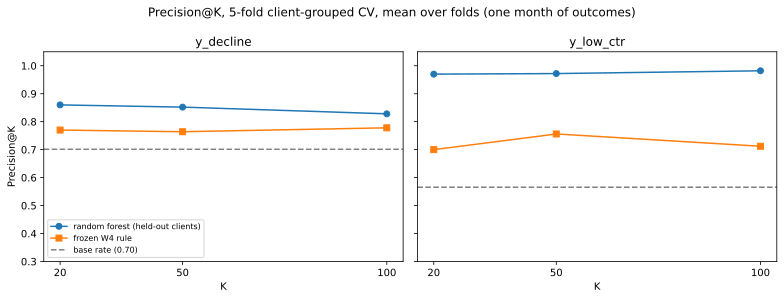

Embedded figure: action_mix.svg


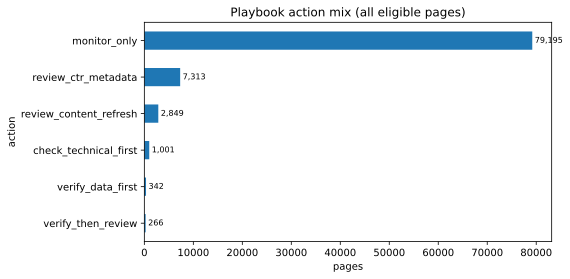

In [7]:
grading = pd.DataFrame(metrics["grading_table"])
print("Saved W7 grading summary:")
display(grading)

for figure_name in ["precision_at_k.svg", "action_mix.svg"]:
    figure_path = FIGURES / figure_name
    if not figure_path.is_file():
        raise FileNotFoundError(f"Expected generated figure is missing: {figure_path}")
    print(f"Embedded figure: {figure_name}")
    display(SVG(filename=str(figure_path)))

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.